# Lesson 1: Linear Regression
Goal: understand the basic machine learning workflow: prepare data, train a model (`fit`) and make predictions (`predict`).


In [16]:
# Import the linear regression model from scikit-learn
from sklearn.linear_model import LinearRegression

# Toy data: apartment size (m²) and monthly rent (CHF), made up for practice
areas = [[35],[50],[65],[80],[100],[120]] # X: features, one row per apartment
rents = [1300, 1650, 1950, 2300, 2750, 3200] # y: labels, the "correct answers"

# Create an empty linear regression model
model = LinearRegression()

# Train the model: find the best line rent = slope * are + intercept
model.fit(areas, rents)

# Inspect what the model has learned
print("Price per extra m²:", round(model.coef_[0], 1), "CHF")
print("Intercept:", round(model.intercept_, 1), "CHF")

# Use the model to predict the rent of a new 90 m² apartment
prediction = model.predict([[90]])
print("Predicted rent for 90 m²:", round(prediction[0]), "CHF")


Price per extra m²: 22.3 CHF
Intercept: 519.2 CHF
Predicted rent for 90 m²: 2526 CHF


## Verifying the model by hand
Linear regression uses least squares. The slope and intercept can be computed directly with a formula, so we check whether we get the same result as scikit-learn.

In [17]:
# Same data as above, but as flat lists (no nested brackets needed here)
x = [35, 50, 65, 80, 100, 120]     # areas in m²
y = [1300, 1650, 1950, 2300, 2750, 3200]  # rents in CHF

# Step 1: averages
x_mean = sum(x) / len(x)
y_mean = sum(y) / len(y)

# Step 2: how strongly x and y move together
s_xy = sum((xi - x_mean) * (yi - y_mean) for xi, yi in zip(x, y, strict=True))

# Step 3: how much x varies around its mean
s_xx = sum((xi - x_mean) ** 2 for xi in x)

# Step 4: least squares formulas
slope = s_xy / s_xx
intercept = y_mean - slope * x_mean

print("Slope (by hand):", round(slope, 1))
print("Intercept (by hand):", round(intercept, 1))


Slope (by hand): 22.3
Intercept (by hand): 519.2


## Experiment 1: Effect of an outlier
What happens if we add one unrealistic apartment (60 m², 4000 CHF)?

In [18]:
# Add one unrealistic apartment to copies of the original data
areas_outlier = areas + [[60]]
rents_outlier = rents  + [4000]

# Train a second, separate model on the new data
model_outlier = LinearRegression()
model_outlier.fit(areas_outlier, rents_outlier)

# Compare both models
print("Slope without outlier:", round(model.coef_[0], 1), "CHF/m²")
print("Slope with outlier:   ", round(model_outlier.coef_[0], 1), "CHF/m²")
print()
print("Intercept without outlier:", round(model.intercept_, 1), "CHF")
print("Intercept with outlier:   ", round(model_outlier.intercept_, 1), "CHF")
print()
print("Prediction for 90 m² without outlier:", round(model.predict([[90]])[0]), "CHF")
print("Prediction for 90 m² with outlier:   ", round(model_outlier.predict([[90]])[0]), "CHF")

Slope without outlier: 22.3 CHF/m²
Slope with outlier:    17.0 CHF/m²

Intercept without outlier: 519.2 CHF
Intercept with outlier:    1211.8 CHF

Prediction for 90 m² without outlier: 2526 CHF
Prediction for 90 m² with outlier:    2741 CHF


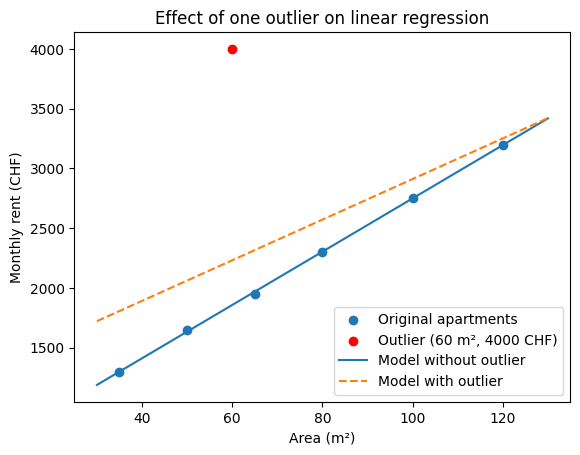

In [19]:
import matplotlib.pyplot as plt

# Two x positions are enough to draw a straight line
line_x = [30, 130]

# Calculate the y values of each line: rent = slope * area + intercept
line_original = [model.coef_[0] * xi + model.intercept_ for xi in line_x]
line_outlier = [model_outlier.coef_[0] * xi + model_outlier.intercept_ for xi in line_x]

# Data points
plt.scatter(x, y, label="Original apartments")
plt.scatter([60], [4000], color="red", label="Outlier (60 m², 4000 CHF)")

# Fitted lines
plt.plot(line_x, line_original, label="Model without outlier")
plt.plot(line_x, line_outlier, linestyle="--", label="Model with outlier")

# Labels and title
plt.xlabel("Area (m²)")
plt.ylabel("Monthly rent (CHF)")
plt.title("Effect of one outlier on linear regression")
plt.legend()
plt.show()

### Observation
- An outlier with a below-average area (60 m²) but a very high rent (4000 CHF) raises the intercept (519 → 1212 CHF) and lowers the slope (22.3 → 17.0 CHF/m²).
- As a result, the model overestimates rents, especially for small apartments. This effect becomes smaller as the area increases.
- The two lines cross at about 131 m². For larger apartments, the effect is reversed: the model with the outlier predicts lower rents than the original model.
- **Why:** Least squares uses squared errors, so a single point far away from the line has a huge influence. Since the outlier lies on the left side, it lifts the left end of the line, while the large apartments keep the right end in place.
- **Takeaway:** Before training a model on real data, always plot the data and check for outliers.

## Experiment 2: Extrapolation
The model was trained on apartments between 35 and 120 m². How reliable are its predictions outside this range?

In [20]:
# Areas inside and far outside the training range (35-120 m²)
test_areas = [10, 90, 300, 1000]

# Predict the rent for each area with the original model
for area in test_areas:
  predicted_rent = model.predict([[area]])[0]
  print(f"{area} m² -> {predicted_rent:.0f} CHF")

10 m² -> 742 CHF
90 m² -> 2526 CHF
300 m² -> 7209 CHF
1000 m² -> 22819 CHF


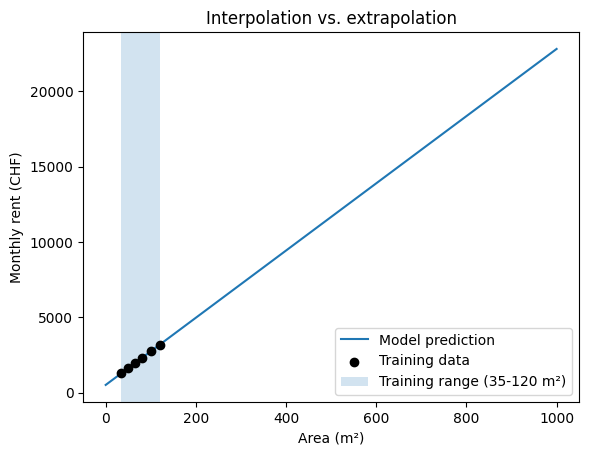

In [27]:
# Draw the model line far beyond the training data
line_x = [0, 1000]
line_y = [model.coef_[0] * xi + model.intercept_ for xi in line_x]

plt.plot(line_x, line_y, label="Model prediction")
plt.scatter(x, y, color="black", zorder=3, label="Training data")
plt.axvspan(35, 120, alpha=0.2, label="Training range (35-120 m²)")

plt.xlabel("Area (m²)")
plt.ylabel("Monthly rent (CHF)")
plt.title("Interpolation vs. extrapolation")
plt.legend()
plt.show()

### Observation
- The model was trained on apartments between 35 and 120 m². Predictions inside this range are called **interpolation** and are relatively reliable.
- Predictions outside this range are called **extrapolation**. The model simply extends the straight line forever, e.g. it predicts 519 CHF for 0 m² and 22,819 CHF for 1000 m².
- **Why this is a problem:** We have no evidence that the relationship is still linear outside the training range. Very small rooms or very large villas follow different pricing rules.
- **Takeaway:** A model never says "I don't know". It is the user's responsibility to check whether a prediction lies within the range of the training data.